# Laboratorio 4 – Segmentación de imágenes con técnicas de agrupación (DermAlpes)

## 0. Importación de librerías y parámetros globales

In [1]:
import os
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline

In [2]:
semilla = 2026           # semilla de K-medias y de la muestra de píxeles para la silueta
lado_max = 128           # lado mayor al que se reduce cada imagen
n_muestra = 2000         # tamaño de la muestra de píxeles para el coeficiente de silueta
rango_k = range(2, 9)    # valores de K a explora
dir_datos = os.path.join('.', 'data')
dir_imgs = os.path.join(dir_datos, 'normal')      # imágenes .jpg
dir_mascaras = os.path.join(dir_datos, 'masks')   # máscaras ISIC

ids_ajuste = ['ISIC_0000085', 'ISIC_0000086', 'ISIC_0000089', 'ISIC_0000094', 'ISIC_0000108',
              'ISIC_0000114', 'ISIC_0000116', 'ISIC_0000122', 'ISIC_0000133', 'ISIC_0000137',
              'ISIC_0000150', 'ISIC_0000153', 'ISIC_0000156', 'ISIC_0000157', 'ISIC_0000112']
len(ids_ajuste)

15

## 1. Pipeline de preparación y representación

### 1.1 Carga de las imágenes

Las imágenes originales miden 2048 × 1536 píxeles. Por eso se reducen a **128 píxeles en el lado mayor**, conservando la proporción. Para esta tarea se va a utilizar la  interpolación por área, la adecuada para reducir tamaño. La reducción pierde detalles finos (pelos, puntos pequeños), lo que es una limitación que se tendrá en cuenta al interpretar resultados. Las máscaras de referencia deberán reducirse al mismo tamaño con vecino más cercano.

In [3]:
def forma_reducida(alto, ancho, lado=lado_max):
    escala = lado / max(alto, ancho)
    return round(alto * escala), round(ancho * escala)


def cargar_imagen(id_img, carpeta=dir_imgs, lado=lado_max):
    bgr = cv2.imread(os.path.join(carpeta, f'{id_img}.jpg'), cv2.IMREAD_COLOR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    alto, ancho = forma_reducida(*rgb.shape[:2], lado)
    return cv2.resize(rgb, (ancho, alto), interpolation=cv2.INTER_AREA)


imagenes = {id_img: cargar_imagen(id_img) for id_img in ids_ajuste}
pd.Series({id_img: imagen.shape for id_img, imagen in imagenes.items()}, name='forma (alto, ancho, canales)')

ISIC_0000085    (96, 128, 3)
ISIC_0000086    (96, 128, 3)
ISIC_0000089    (96, 128, 3)
ISIC_0000094    (96, 128, 3)
ISIC_0000108    (96, 128, 3)
ISIC_0000114    (96, 128, 3)
ISIC_0000116    (96, 128, 3)
ISIC_0000122    (96, 128, 3)
ISIC_0000133    (96, 128, 3)
ISIC_0000137    (96, 128, 3)
ISIC_0000150    (96, 128, 3)
ISIC_0000153    (96, 128, 3)
ISIC_0000156    (96, 128, 3)
ISIC_0000157    (84, 128, 3)
ISIC_0000112    (96, 128, 3)
Name: forma (alto, ancho, canales), dtype: object

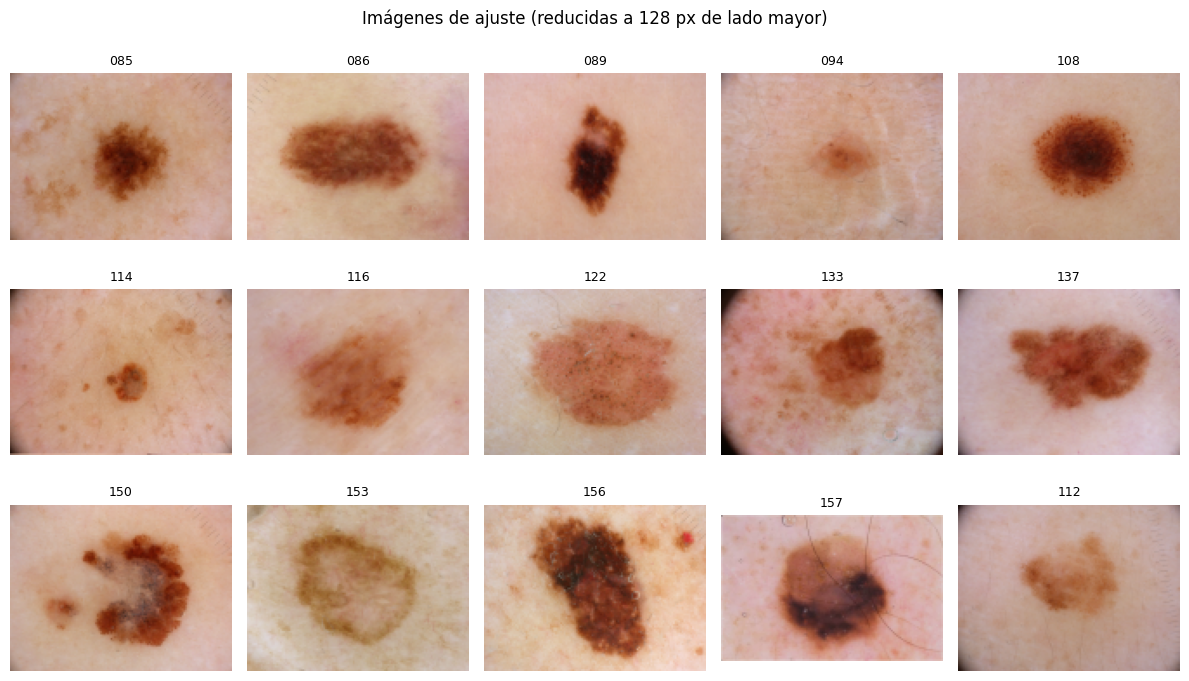

In [4]:
def abreviar(id_img):
    return id_img.replace('ISIC_0000', '')


def mostrar_imgs(dic_imgs, titulo, columnas=5):
    filas = int(np.ceil(len(dic_imgs) / columnas))
    fig, ejes = plt.subplots(filas, columnas, layout='tight', figsize=(12, 2.4 * filas))
    ejes = np.atleast_2d(ejes)
    for eje in ejes.ravel():
        eje.axis('off')
    for eje, (id_img, imagen) in zip(ejes.ravel(), dic_imgs.items()):
        eje.imshow(imagen)
        eje.set_title(abreviar(id_img), fontsize=9)
    plt.suptitle(titulo)
    plt.show()


mostrar_imgs(imagenes, 'Imágenes de ajuste (reducidas a 128 px de lado mayor)')

### 1.2 Preparación de las máscaras de referencia

Las máscaras contienen 0 (piel) y 255 (lesión). La función siguiente las convierte a 0 y 1 y las redimensiona con **interpolación por vecino más cercano** para conservar valores binarios y tener exactamente las mismas dimensiones que la imagen reducida. Se verifican la forma y los valores de las 15 máscaras de ajuste.

In [5]:
def cargar_mascara_referencia(id_img, forma_hw, carpeta=dir_mascaras):
    ruta = os.path.join(carpeta, f'{id_img}_Segmentation.png')
    mascara = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)
    if mascara is None:
        raise FileNotFoundError(ruta)
    alto, ancho = forma_hw
    mascara = cv2.resize(mascara, (ancho, alto), interpolation=cv2.INTER_NEAREST)
    return (mascara > 127).astype(np.uint8)


mascaras_ref = {id_img: cargar_mascara_referencia(id_img, imagenes[id_img].shape[:2]) for id_img in ids_ajuste}

for id_img in ids_ajuste:
    assert mascaras_ref[id_img].shape == imagenes[id_img].shape[:2]
    assert set(np.unique(mascaras_ref[id_img])) <= {0, 1}

area_ref = pd.Series({abreviar(i): m.mean() for i, m in mascaras_ref.items()}, name='fracción de lesión')
print(f'{len(mascaras_ref)} máscaras cargadas. Fracción de la imagen ocupada por la lesión: '
      f'mín {area_ref.min():.3f}, media {area_ref.mean():.3f}, máx {area_ref.max():.3f}')
area_ref.round(3).to_frame().T

15 máscaras cargadas. Fracción de la imagen ocupada por la lesión: mín 0.031, media 0.223, máx 0.391


,085,086,089,094,108,114,116,122,133,137,150,153,156,157,112
fracción de lesión,0.127,0.234,0.121,0.059,0.185,0.031,0.361,0.391,0.142,0.244,0.323,0.277,0.314,0.331,0.202


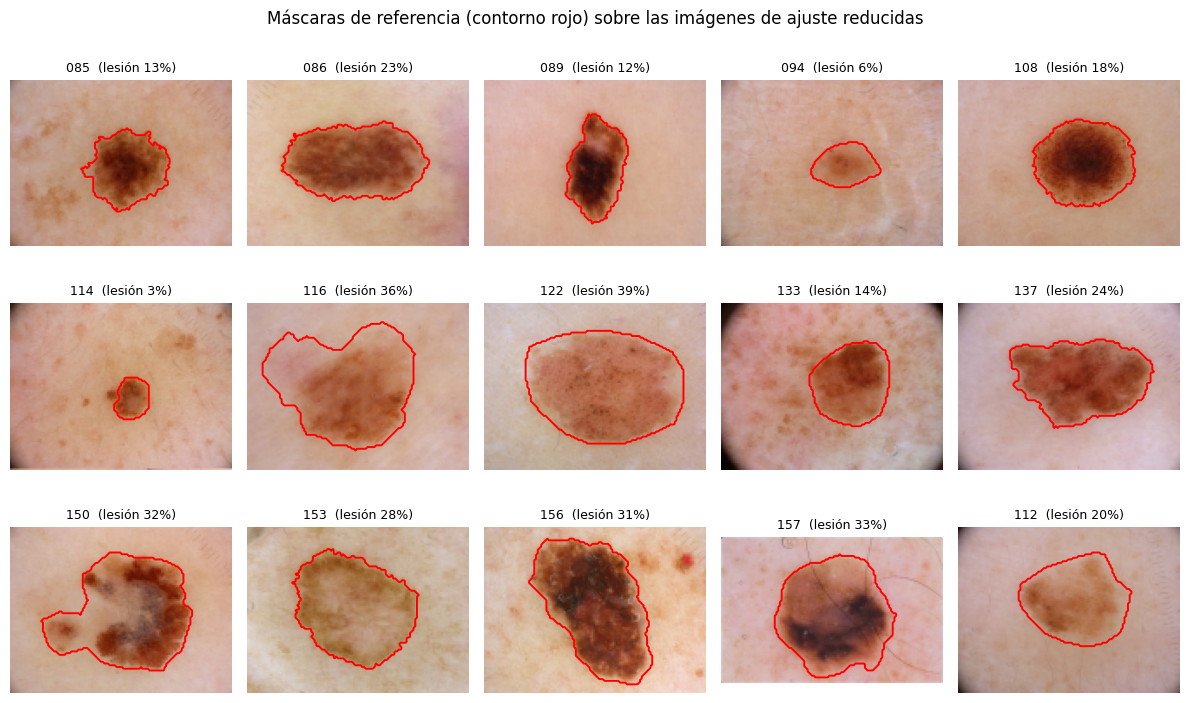

In [6]:
fig, ejes = plt.subplots(3, 5, layout='tight', figsize=(12, 7.5))
for eje, id_img in zip(ejes.ravel(), ids_ajuste):
    eje.imshow(imagenes[id_img])
    eje.contour(mascaras_ref[id_img], levels=[0.5], colors='red', linewidths=1.4)
    eje.set_title(f'{abreviar(id_img)}  (lesión {mascaras_ref[id_img].mean():.0%})', fontsize=9)
    eje.axis('off')
plt.suptitle('Máscaras de referencia (contorno rojo) sobre las imágenes de ajuste reducidas')
plt.show()

### 1.3 Representación de cada píxel y pipeline de Scikit-learn

Cada imagen se convierte en una matriz con **un píxel por fila**, las características con R, G, B divididos por 255 y las coordenadas x (columna) e y (fila) divididas por (W − 1) y (H − 1), siendo **W** el ancho y **H** el alto de la imagen, de modo que todo queda en [0, 1] antes de ponderar. Decisiones de diseño:

- **Transformador propio** (CaracteristicasPixel): Scikit-learn no trae un transformador que convierta una imagen en píxeles con coordenadas, por lo que no hay fuga de información entre imágenes.
- **No se usa `StandardScaler`**: estandarizar cada columna alteraría la escala relativa color/posición, que es justamente lo que controlan los hiperparámetros β y λ. La normalización a [0, 1] ya hace comparables ambas fuentes de información.

In [7]:
class CaracteristicasPixel(BaseEstimator, TransformerMixin):
    def __init__(self, beta=1.0, lam=0.0):
        self.beta = beta
        self.lam = lam

    def fit(self, imagen, y=None):
        return self

    def transform(self, imagen):
        if self.beta < 0 or self.lam < 0 or (self.beta == 0 and self.lam == 0):
            raise ValueError('beta y lam deben ser >= 0 y no ambos cero.')
        imagen = np.asarray(imagen)
        alto, ancho, _ = imagen.shape
        rgb = imagen.reshape(-1, 3).astype(np.float64) / 255.0
        filas, columnas = np.meshgrid(np.arange(alto), np.arange(ancho), indexing='ij')
        x = columnas.ravel() / (ancho - 1)
        y = filas.ravel() / (alto - 1)
        return np.column_stack([self.beta * rgb, self.lam * x, self.lam * y])


def construir_pipeline(beta=1.0, lam=0.0, k=3, sem=semilla):
    return Pipeline([
        ('pixeles', CaracteristicasPixel(beta=beta, lam=lam)),
        ('kmeans', KMeans(n_clusters=k, n_init=3, random_state=sem)),
    ])

In [8]:
# Verificación del transformador sobre una imagen
pipeline = construir_pipeline()
imagen_0 = imagenes['ISIC_0000085']
columnas = ['beta*R', 'beta*G', 'beta*B', 'lam*x', 'lam*y']

maximos = []
for nombre, (beta, lam) in {'color + posición (1, 1)': (1, 1), 'pesos (0.5, 2)': (0.5, 2),
                            'solo color (1, 0)': (1, 0), 'solo posición (0, 1)': (0, 1)}.items():
    pipeline.set_params(pixeles__beta=beta, pixeles__lam=lam)
    matriz = pipeline.named_steps['pixeles'].transform(imagen_0)
    assert matriz.shape == (imagen_0.shape[0] * imagen_0.shape[1], 5)
    maximos.append(pd.Series(matriz.max(axis=0), index=columnas, name=nombre))
    if lam == 0: assert np.all(matriz[:, 3:] == 0)
    if beta == 0: assert np.all(matriz[:, :3] == 0)

print(f'Imagen {abreviar("ISIC_0000085")}: {imagen_0.shape[0]} x {imagen_0.shape[1]} = {len(matriz)} píxeles, matriz de {matriz.shape[0]} x {matriz.shape[1]}')
pd.DataFrame(maximos).round(3)

Imagen 085: 96 x 128 = 12288 píxeles, matriz de 12288 x 5


,beta*R,beta*G,beta*B,lam*x,lam*y
"color + posición (1, 1)",0.839,0.714,0.710,1.0,1.0
"pesos (0.5, 2)",0.420,0.357,0.355,2.0,2.0
"solo color (1, 0)",0.839,0.714,0.710,0.0,0.0
"solo posición (0, 1)",0.000,0.000,0.000,1.0,1.0


Las verificaciones confirman la forma (H·W) × 5, que con β = λ = 1 las columnas máximas no superan 1 (los máximos de color son < 1 porque estas imágenes no saturan los canales), y que los casos extremos anulan las columnas correspondientes. Ahora se muestra que **el mismo pipeline** produce agrupaciones muy distintas cambiando solo β, λ y K:

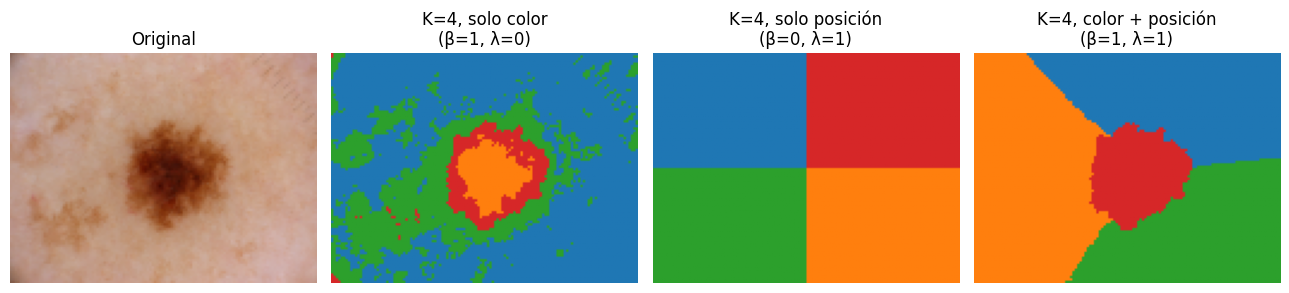

In [9]:
configuraciones = {'solo color\n(β=1, λ=0)': (1, 0), 'solo posición\n(β=0, λ=1)': (0, 1),
                   'color + posición\n(β=1, λ=1)': (1, 1)}

fig, ejes = plt.subplots(1, 4, layout='tight', figsize=(13, 3.2))
ejes[0].imshow(imagen_0)
ejes[0].set_title('Original')
for eje, (nombre, (beta, lam)) in zip(ejes[1:], configuraciones.items()):
    pipeline = construir_pipeline().set_params(pixeles__beta=beta, pixeles__lam=lam, kmeans__n_clusters=4)
    etiquetas = pipeline.fit_predict(imagen_0).reshape(imagen_0.shape[:2])
    eje.imshow(etiquetas, cmap='tab10', vmin=0, vmax=9)
    eje.set_title(f'K=4, {nombre}')
for eje in ejes:
    eje.axis('off')
plt.show()

Con solo color los grupos corresponden a zonas de tono parecido sin importar dónde estén, con solo posición se obtiene una partición geométrica independiente de la imagen, con ambos, los grupos son tonalmente homogéneos y compactos.

## 2. Agrupación y selección de K

### 2.1 Diez combinaciones de (β, λ)

K-medias usa distancias euclídeas, así que **multiplicar β y λ por la misma constante no cambia los grupos**. Lo único que importa es la razón λ/β. Por eso se fija β = 1 y se varía λ con ocho razones distintas, más los dos extremos: solo color (λ = 0) y solo posición (β = 0).

In [10]:
razones = [0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0]
combinaciones = [(1.0, 0.0)] + [(1.0, r) for r in razones] + [(0.0, 1.0)]

def nombre_combinacion(beta, lam):
    if lam == 0:
        return 'solo color'
    if beta == 0:
        return 'solo posición'
    return f'λ/β={lam / beta:g}'


nombres_comb = [nombre_combinacion(beta, lam) for beta, lam in combinaciones]
pd.DataFrame({'beta': [beta for beta, _ in combinaciones], 'lam': [lam for _, lam in combinaciones]},
             index=nombres_comb)

,beta,lam
solo color,1.0,0.00
λ/β=0.1,1.0,0.10
λ/β=0.25,1.0,0.25
λ/β=0.5,1.0,0.50
λ/β=0.75,1.0,0.75
λ/β=1,1.0,1.00
λ/β=1.5,1.0,1.50
λ/β=2,1.0,2.00
λ/β=4,1.0,4.00
solo posición,0.0,1.00


In [11]:
def indices_muestra_silueta(n_pixeles, tamano=n_muestra, sem=semilla):
    return np.random.default_rng(sem).choice(n_pixeles, size=min(tamano, n_pixeles), replace=False)


def explorar_imagen(id_img, imagen, combs=combinaciones, valores_k=rango_k):
    indices = indices_muestra_silueta(imagen.shape[0] * imagen.shape[1])
    pipeline = construir_pipeline()
    registros, mejores = [], {}
    for beta, lam in combs:
        pipeline.set_params(pixeles__beta=beta, pixeles__lam=lam)
        matriz = pipeline.named_steps['pixeles'].transform(imagen)
        mejor = (-np.inf, None, None)   # (silueta, k, etiquetas)
        for k in valores_k:
            pipeline.set_params(kmeans__n_clusters=k)
            etiquetas = pipeline.fit_predict(imagen)
            hay_dos_grupos = len(np.unique(etiquetas[indices])) > 1
            silueta = silhouette_score(matriz[indices], etiquetas[indices]) if hay_dos_grupos else np.nan
            registros.append(dict(imagen=id_img, combo=nombre_combinacion(beta, lam), beta=beta, lam=lam,
                                  k=k, silueta=silueta))
            if silueta > mejor[0]:
                mejor = (silueta, k, etiquetas.reshape(imagen.shape[:2]))
        mejores[(id_img, nombre_combinacion(beta, lam))] = dict(k=mejor[1], silueta=mejor[0], etiquetas=mejor[2])
    return registros, mejores

### 2.2 Selección de K por coeficiente de silueta

Para cada imagen de ajuste y cada combinación se ajusta K-medias con K entre 2 y 8 y se elige el K de **mayor silueta**.

- **Tamaño de la muestra:** 2000 píxeles
- **Semilla:** 2026 (`np.random.default_rng(2026)`), muestreo sin reemplazo.
- Se usa **la misma muestra** para todos los K y combinaciones de una imagen, de modo que las comparaciones entre K sean limpias.
- K-medias: n_init=3, random_state=2026, no se usan máscaras de referencia.

In [12]:
inicio = time.time()
registros, mejores = [], {}
for id_img, imagen in imagenes.items():
    reg, mej = explorar_imagen(id_img, imagen)
    registros += reg
    mejores.update(mej)
resultados = pd.DataFrame(registros)
n_pix = imagenes[ids_ajuste[0]].shape[0] * imagenes[ids_ajuste[0]].shape[1]
print(f'{len(resultados)} ajustes de K-medias ({len(imagenes)} imágenes x {len(combinaciones)} combinaciones x {len(rango_k)} valores de K)')
print(f'Muestra para la silueta: {n_muestra} píxeles de {n_pix} por imagen, semilla = {semilla}')

1050 ajustes de K-medias (15 imágenes x 10 combinaciones x 7 valores de K)
Muestra para la silueta: 2000 píxeles de 12288 por imagen, semilla = 2026


### 2.3 Resultados

In [13]:
mejor_k = resultados.loc[resultados.groupby(['imagen', 'combo'])['silueta'].idxmax()]
tabla_k = mejor_k.pivot(index='imagen', columns='combo', values='k')[nombres_comb]
tabla_k.index = [abreviar(i) for i in tabla_k.index]
tabla_k.index.name = 'imagen'
tabla_k

combo,solo color,λ/β=0.1,λ/β=0.25,λ/β=0.5,λ/β=0.75,λ/β=1,λ/β=1.5,λ/β=2,λ/β=4,solo posición
imagen,,,,,,,,,,
085,2,2,2,2,5,5,5,5,5,4
086,2,2,2,2,5,5,5,5,5,4
089,2,2,2,2,5,5,5,5,5,4
094,2,2,5,5,5,5,5,4,4,4
108,2,2,2,2,5,5,5,5,5,4
112,2,2,2,5,5,5,5,5,4,4
114,2,2,2,5,5,5,4,4,4,4
116,2,2,2,5,5,5,5,5,5,4
122,2,2,2,5,5,5,5,5,5,4


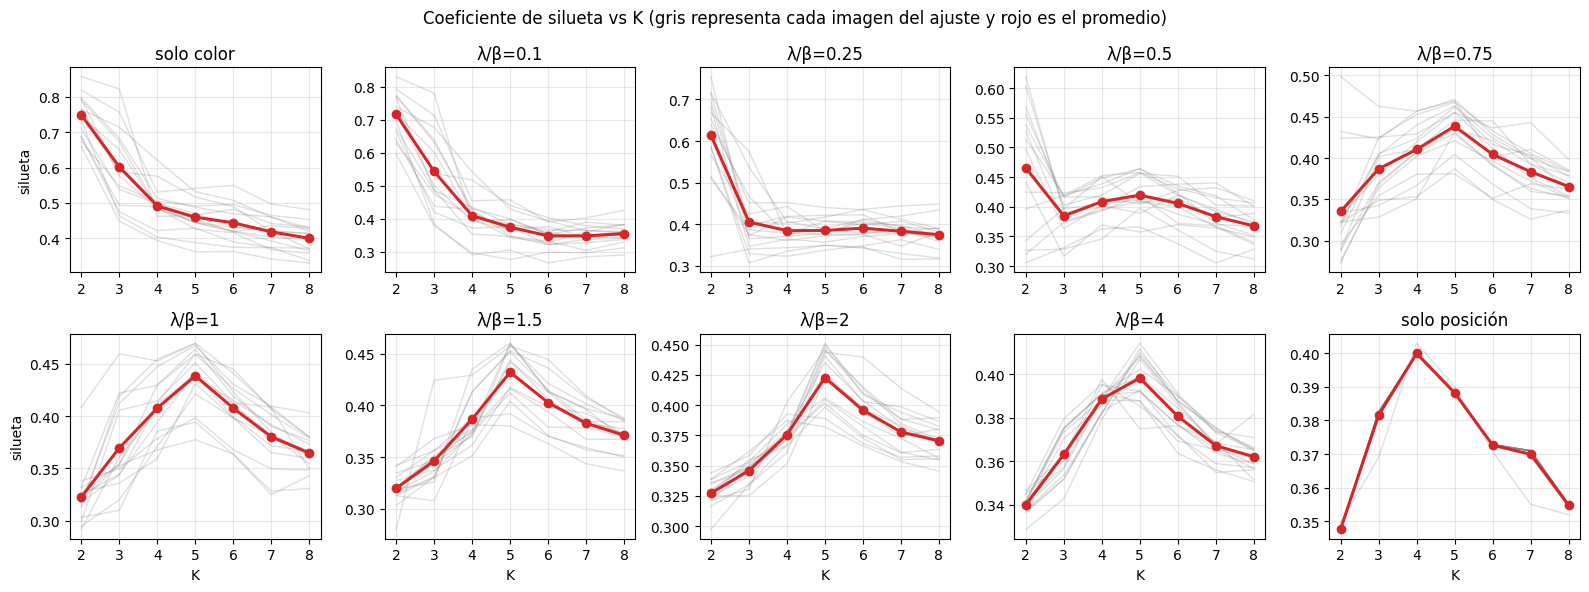

In [14]:
fig, ejes = plt.subplots(2, 5, layout='tight', figsize=(16, 6))
for eje, nombre in zip(ejes.ravel(), nombres_comb):
    sub = resultados[resultados.combo == nombre].pivot(index='k', columns='imagen', values='silueta')
    eje.plot(sub.index, sub.values, color='gray', alpha=0.25, lw=1)
    eje.plot(sub.index, sub.mean(axis=1), color='C3', lw=2.2, marker='o', label='promedio')
    eje.set_title(nombre)
    eje.set_xticks(list(rango_k))
    eje.grid(alpha=0.3)
for eje in ejes[1]:
    eje.set_xlabel('K')
for eje in ejes[:, 0]:
    eje.set_ylabel('silueta')
plt.suptitle('Coeficiente de silueta vs K (gris representa cada imagen del ajuste y rojo es el promedio)')
plt.show()

In [15]:
resumen = mejor_k.groupby('combo').agg(
    silueta_media=('silueta', 'mean'),
    k_mediana=('k', 'median'),
    k_moda=('k', lambda s: s.mode().iloc[0]),
    n_k2=('k', lambda s: int((s == 2).sum())),
    n_k_ge5=('k', lambda s: int((s >= 5).sum())),
).loc[nombres_comb].round(3)
resumen

,silueta_media,k_mediana,k_moda,n_k2,n_k_ge5
combo,,,,,
solo color,0.749,2.0,2,15,0
λ/β=0.1,0.716,2.0,2,15,0
λ/β=0.25,0.616,2.0,2,14,1
λ/β=0.5,0.492,2.0,2,9,6
λ/β=0.75,0.441,5.0,5,1,14
λ/β=1,0.439,5.0,5,0,15
λ/β=1.5,0.432,5.0,5,0,14
λ/β=2,0.423,5.0,5,0,13
λ/β=4,0.401,5.0,5,0,10


**Lectura de los resultados (15 imágenes de ajuste):**

- **Solo color y λ/β ≤ 0.25:** la silueta elige K = 2 en prácticamente todas las imágenes (15/15, 15/15 y 14/15). Es coherente con la estructura dominante de estas imágenes con las clase de lunar/lesiín y piel. La silueta media es la más alta (0.75 con solo color).
- **λ/β ≥ 0.75:** el K pasa a 5 en la mayoría (14, 15, 14, 13 y 10 de 15). Con mucho peso espacial, K-medias tiende a partir la imagen en regiones compactas, el patrón típico es *cuatro regiones de piel + un grupo central para la lesión*.
- **λ/β = 0.5** es un punto de transición (9 imágenes con K = 2 y 6 con K ≥ 5).
- **Solo posición:** K = 4 en las 15 imágenes y silueta 0.40. Es un resultado esperable, pues sin color la partición no depende del contenido, solo de la geometría.

## 3. Criterio de construcción de la máscara de la lesión

K-medias agrupa los píxeles pero **no dice cuál grupo es la lesión**. Se necesita un criterio automático que use solo las características de los grupos (color, tamaño, ubicación), sin hacer uso de máscaras de referencia.

### 3.1 Descriptores de cada grupo

Con base en cómo lucen las imágenes de ajuste, una lesión suele ser: 

**Más oscura o más pigmentada que la piel alrededor**

**Central** (las fotos están encuadradas sobre la lesión) 

**Un solo objeto compacto**. 

In [16]:
def descriptores_grupos(imagen, etiquetas, fraccion_marco=0.10):
    alto, ancho, _ = imagen.shape
    rgb = imagen.reshape(-1, 3).astype(np.float64) / 255.0
    lum = rgb @ np.array([0.299, 0.587, 0.114])
    filas, columnas = np.meshgrid(np.arange(alto), np.arange(ancho), indexing='ij')
    x, y = columnas.ravel() / (ancho - 1), filas.ravel() / (alto - 1)
    grosor = max(1, round(fraccion_marco * min(alto, ancho)))
    marco = ((filas < grosor) | (filas >= alto - grosor) | (columnas < grosor) | (columnas >= ancho - grosor)).ravel()
    piel = np.median(rgb[marco], axis=0)
    etiq = etiquetas.ravel()

    datos = {}
    for grupo in np.unique(etiq):
        sel = etiq == grupo
        color_medio = rgb[sel].mean(axis=0)
        datos[grupo] = dict(
            tamano=sel.mean(),
            luminancia=lum[sel].mean(),
            contraste=np.linalg.norm(color_medio - piel),
            dist_centro=np.hypot(x[sel].mean() - 0.5, y[sel].mean() - 0.5) / np.hypot(0.5, 0.5),
            frac_borde=marco[sel].mean(),
        )
    tabla = pd.DataFrame(datos).T
    tabla.index.name = 'grupo'
    tabla['puntaje'] = tabla.contraste * (1 - tabla.dist_centro) * (1 - tabla.frac_borde)
    return tabla, piel

### 3.2 Dos criterios

**Criterio 1 – oscuro (solo color).** La lesión es el grupo de menor luminancia media. No tiene parámetros y sirve de referencia. Falla cuando hay algo más oscuro que la lesión como pelos y, como trabaja a nivel de grupo, hereda las motas sueltas que K-medias agrupe con la lesión.

**Criterio 2 – puntaje (color + ubicación + forma).**

1. Se calcula para cada grupo $\text{puntaje} = \text{contraste} \times (1-\text{dist\_centro}) \times (1-\text{frac\_borde})$.
2. Se eligen los grupos con puntaje ≥ τ · (mejor puntaje), con τ = 0.5, porque con K grande la lesión puede repartirse en varios grupos.
3. De la unión de esos grupos se conserva el **componente conexo más grande** y se rellenan sus huecos. Elimina motas y esquinas, y cierra zonas claras en el interior de la lesión.

El contraste se mide contra el marco exterior y no contra la mediana de toda la imagen, porque una lesión grande puede ocupar más de la mitad de la imagen, mientras que el marco casi siempre es piel.

In [17]:
from scipy import ndimage


def mascara_mas_oscuro(imagen, etiquetas):
    """Criterio 1 (solo color)"""
    tabla, _ = descriptores_grupos(imagen, etiquetas)
    elegidos = [tabla.luminancia.idxmin()]
    return np.isin(etiquetas, elegidos).astype(np.uint8), elegidos


def mayor_componente_rellena(mascara):
    componentes, n_comp = ndimage.label(mascara, structure=np.ones((3, 3)))
    if n_comp == 0:
        return mascara
    tamanos = np.bincount(componentes.ravel())[1:]
    principal = componentes == (np.argmax(tamanos) + 1)
    return ndimage.binary_fill_holes(principal).astype(np.uint8)

tau = 0.5
def mascara_puntaje(imagen, etiquetas, umbral_rel=tau, limpiar=True):
    """Criterio 2"""
    tabla, _ = descriptores_grupos(imagen, etiquetas)
    elegidos = tabla.index[tabla.puntaje >= umbral_rel * tabla.puntaje.max()].tolist()
    mascara = np.isin(etiquetas, elegidos).astype(np.uint8)
    if limpiar:
        mascara = mayor_componente_rellena(mascara)
    return mascara, elegidos


criterios = {'oscuro': mascara_mas_oscuro, 'puntaje': mascara_puntaje}

In [18]:
ejemplo = mejores[('ISIC_0000085', 'λ/β=0.5')]
tabla_desc, piel = descriptores_grupos(imagenes['ISIC_0000085'], ejemplo['etiquetas'])
print(f"K elegido por silueta: {ejemplo['k']}, color de piel de referencia (RGB en [0,1]): {np.round(piel, 2)}")
_, elegido_1 = mascara_mas_oscuro(imagenes['ISIC_0000085'], ejemplo['etiquetas'])
_, elegido_2 = mascara_puntaje(imagenes['ISIC_0000085'], ejemplo['etiquetas'])
print(f'Grupo(s) elegido(s) -> criterio "oscuro": {elegido_1}   criterio "puntaje": {elegido_2}')
tabla_desc.round(3)

K elegido por silueta: 2, color de piel de referencia (RGB en [0,1]): [0.78 0.62 0.56]
Grupo(s) elegido(s) -> criterio "oscuro": [np.int32(0)]   criterio "puntaje": [0]


,tamano,luminancia,contraste,dist_centro,frac_borde,puntaje
grupo,,,,,,
0,0.106,0.316,0.629,0.058,0.006,0.589
1,0.894,0.646,0.040,0.007,0.371,0.025


Ejemplo de descriptores en la imagen 085: el grupo 0 (lunar) tiene contraste alto, está cerca del centro y casi no toca el borde; Por el otro lado, el grupo 1 (piel) está perfectamente centrado  pero su contraste es muy bajo, además el 37 % de sus píxeles están en el marco. Ambos criterios eligen el grupo 0.

### 3.3 Aplicación a las 15 imágenes × 10 combinaciones

Aquí se hacen chequeos **sin comparar contra las máscaras**. Además, una adaptación del criterio 2, con y sin el paso de limpieza.

In [19]:
from functools import partial

variantes = {'oscuro': mascara_mas_oscuro,
             'puntaje sin limpieza': partial(mascara_puntaje, limpiar=False),
             'puntaje': mascara_puntaje}

filas, mascaras = [], {}
for (id_img, combo), mejor in mejores.items():
    for nombre, criterio in variantes.items():
        mascara, elegidos = criterio(imagenes[id_img], mejor['etiquetas'])
        mascaras[(id_img, combo, nombre)] = mascara
        n_comp = ndimage.label(mascara, structure=np.ones((3, 3)))[1]
        filas.append(dict(imagen=id_img, combo=combo, variante=nombre, area=mascara.mean(), n_comp=n_comp, k=mejor['k']))
diagnostico = pd.DataFrame(filas)

diagnostico['degenerada'] = (diagnostico.area < 0.02) | (diagnostico.area > 0.80)
tabla1 = diagnostico[diagnostico.variante != 'puntaje sin limpieza'].pivot_table(
    index='combo', columns='variante', values=['area', 'degenerada']).loc[nombres_comb]
tabla1.columns = [f'{medida} ({variante})' for medida, variante in tabla1.columns]
tabla1 = tabla1.rename(columns={'area (oscuro)': 'área media (oscuro)', 'area (puntaje)': 'área media (puntaje)',
                                'degenerada (oscuro)': '% degeneradas (oscuro)',
                                'degenerada (puntaje)': '% degeneradas (puntaje)'})
tabla1[['% degeneradas (oscuro)', '% degeneradas (puntaje)']] *= 100
print(f'Referencia: la lesión ocupa entre {area_ref.min():.0%} y {area_ref.max():.0%} de la imagen (media {area_ref.mean():.0%}) en las 15 imágenes de ajuste.')
tabla1.round(2)

Referencia: la lesión ocupa entre 3% y 39% de la imagen (media 22%) en las 15 imágenes de ajuste.


,área media (oscuro),área media (puntaje),% degeneradas (oscuro),% degeneradas (puntaje)
combo,,,,
solo color,0.19,0.18,0.0,0.00
λ/β=0.1,0.19,0.18,0.0,0.00
λ/β=0.25,0.19,0.18,0.0,0.00
λ/β=0.5,0.18,0.18,0.0,0.00
λ/β=0.75,0.18,0.18,0.0,0.00
λ/β=1,0.18,0.18,0.0,0.00
λ/β=1.5,0.19,0.19,0.0,0.00
λ/β=2,0.19,0.24,0.0,6.67
λ/β=4,0.20,0.35,0.0,6.67


In [20]:
def iou(a, b):
    union = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / union if union else 1.0


tabla2 = diagnostico.pivot_table(index='combo', columns='variante', values='n_comp').loc[nombres_comb]
tabla2 = tabla2[['oscuro', 'puntaje sin limpieza', 'puntaje']]
tabla2.columns = [f'componentes ({c})' for c in tabla2.columns]
for variante, columna in [('puntaje sin limpieza', 'IoU oscuro vs puntaje sin limpieza'),
                          ('puntaje', 'IoU oscuro vs puntaje')]:
    tabla2[columna] = pd.Series({c: np.mean([iou(mascaras[(i, c, 'oscuro')], mascaras[(i, c, variante)])
                                             for i in ids_ajuste]) for c in nombres_comb})
tabla2.round(2)

,componentes (oscuro),componentes (puntaje sin limpieza),componentes (puntaje),IoU oscuro vs puntaje sin limpieza,IoU oscuro vs puntaje
combo,,,,,
solo color,7.73,7.73,1.0,1.00,0.91
λ/β=0.1,8.13,8.13,1.0,1.00,0.91
λ/β=0.25,6.20,6.20,1.0,1.00,0.92
λ/β=0.5,5.73,5.73,1.0,1.00,0.94
λ/β=0.75,4.73,4.73,1.0,1.00,0.97
λ/β=1,3.33,3.33,1.0,1.00,0.99
λ/β=1.5,2.40,2.40,1.0,1.00,1.00
λ/β=2,1.40,1.40,1.0,0.95,0.95
λ/β=4,1.00,1.00,1.0,0.82,0.82


**Qué muestran los chequeos:**

- **Con color dominante (λ/β ≤ 1.5)** ambos criterios dan áreas similares y ninguna máscara degenerada.
- **Con λ/β ≥ 2 el criterio 2 se infla** (área media 0.24 y 0.35) porque los grupos son regiones espaciales que mezclan lesión y piel, y al unir los de puntaje similar se agrega piel. Con **solo posición** la máscara es arbitraria (área media 0.73, 13 % degeneradas), sin color no hay forma de distinguir lesión de piel.
- **Adaptación limpieza.** La selección por puntaje sin limpieza produce exactamente las mismas máscaras que el grupo más oscuro mientras λ/β ≤ 1.5. En estas imágenes el grupo de mayor contraste es también el más oscuro. **La mejora real del criterio 2 viene del paso de limpieza**, pues el criterio 1 deja en promedio 7–8 componentes conexas con color dominante (motas, esquinas), y el criterio 2 deja siempre 1.

### 3.4 Visualización de los grupos y las máscaras

Ahora, vamos a proceder a comparar las mascaras originales, con la adpatación de ambos criterios, y probar desde un punto de vista visual, el desempeño de ambos al momento de la agrupación.

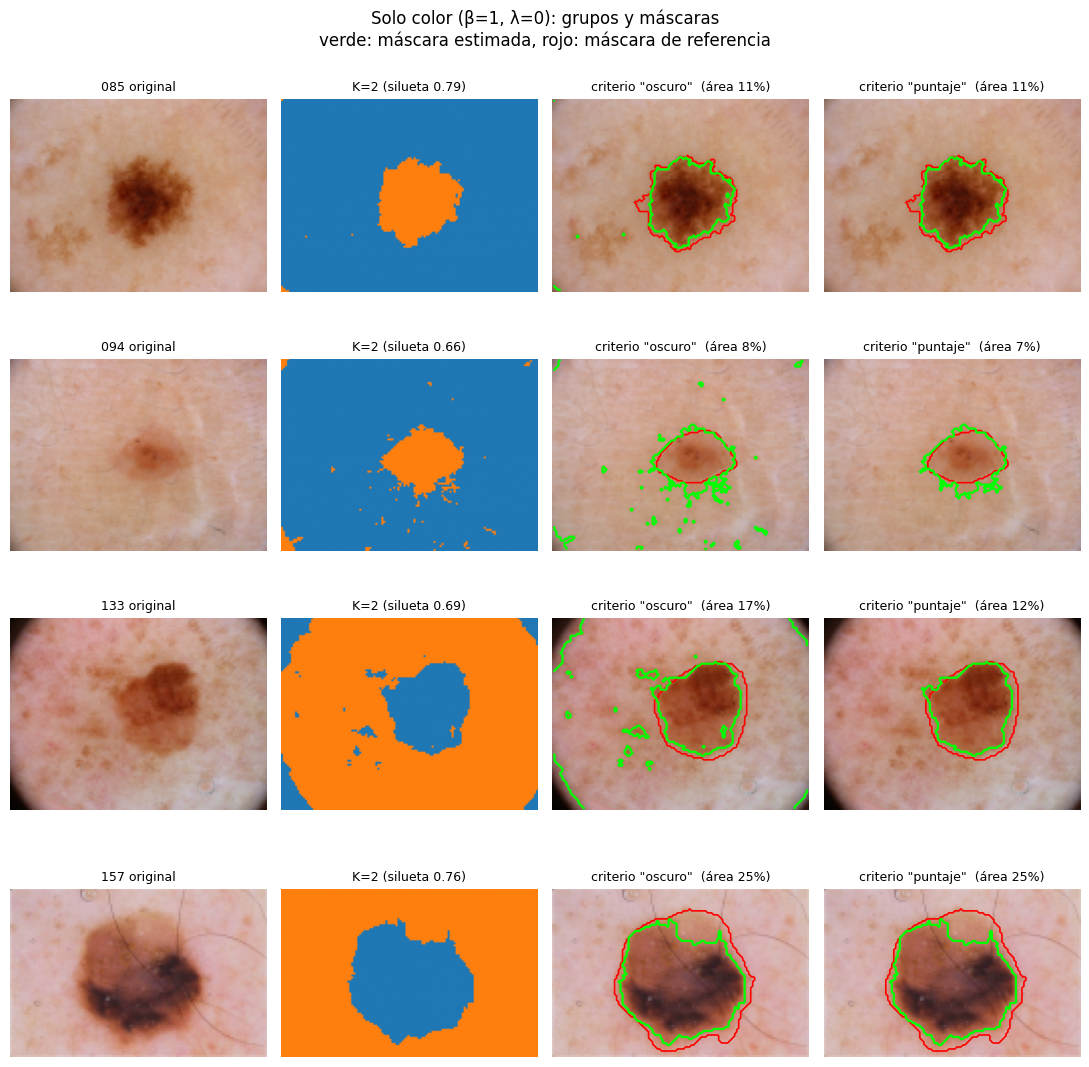

In [21]:
def mostrar_mascaras(combo, ids, titulo):
    fig, ejes = plt.subplots(len(ids), 4, layout='tight', figsize=(11, 2.7 * len(ids) + 0.6))
    for fila, id_img in enumerate(ids):
        mejor = mejores[(id_img, combo)]
        ejes[fila, 0].imshow(imagenes[id_img])
        ejes[fila, 0].set_title(f'{abreviar(id_img)} original', fontsize=9)
        ejes[fila, 1].imshow(mejor['etiquetas'], cmap='tab10', vmin=0, vmax=9)
        ejes[fila, 1].set_title(f"K={mejor['k']} (silueta {mejor['silueta']:.2f})", fontsize=9)
        for col, nombre in enumerate(criterios, start=2):
            mascara = mascaras[(id_img, combo, nombre)]
            ejes[fila, col].imshow(imagenes[id_img])
            ejes[fila, col].contour(mascaras_ref[id_img], levels=[0.5], colors='red', linewidths=1.2)
            ejes[fila, col].contour(mascara, levels=[0.5], colors='lime', linewidths=1.6)
            ejes[fila, col].set_title(f'criterio "{nombre}"  (área {mascara.mean():.0%})', fontsize=9)
    for eje in ejes.ravel():
        eje.axis('off')
    plt.suptitle(titulo + '\nverde: máscara estimada, rojo: máscara de referencia')
    plt.show()


ejemplos = ['ISIC_0000085', 'ISIC_0000094', 'ISIC_0000133', 'ISIC_0000157']
mostrar_mascaras('solo color', ejemplos, 'Solo color (β=1, λ=0): grupos y máscaras')

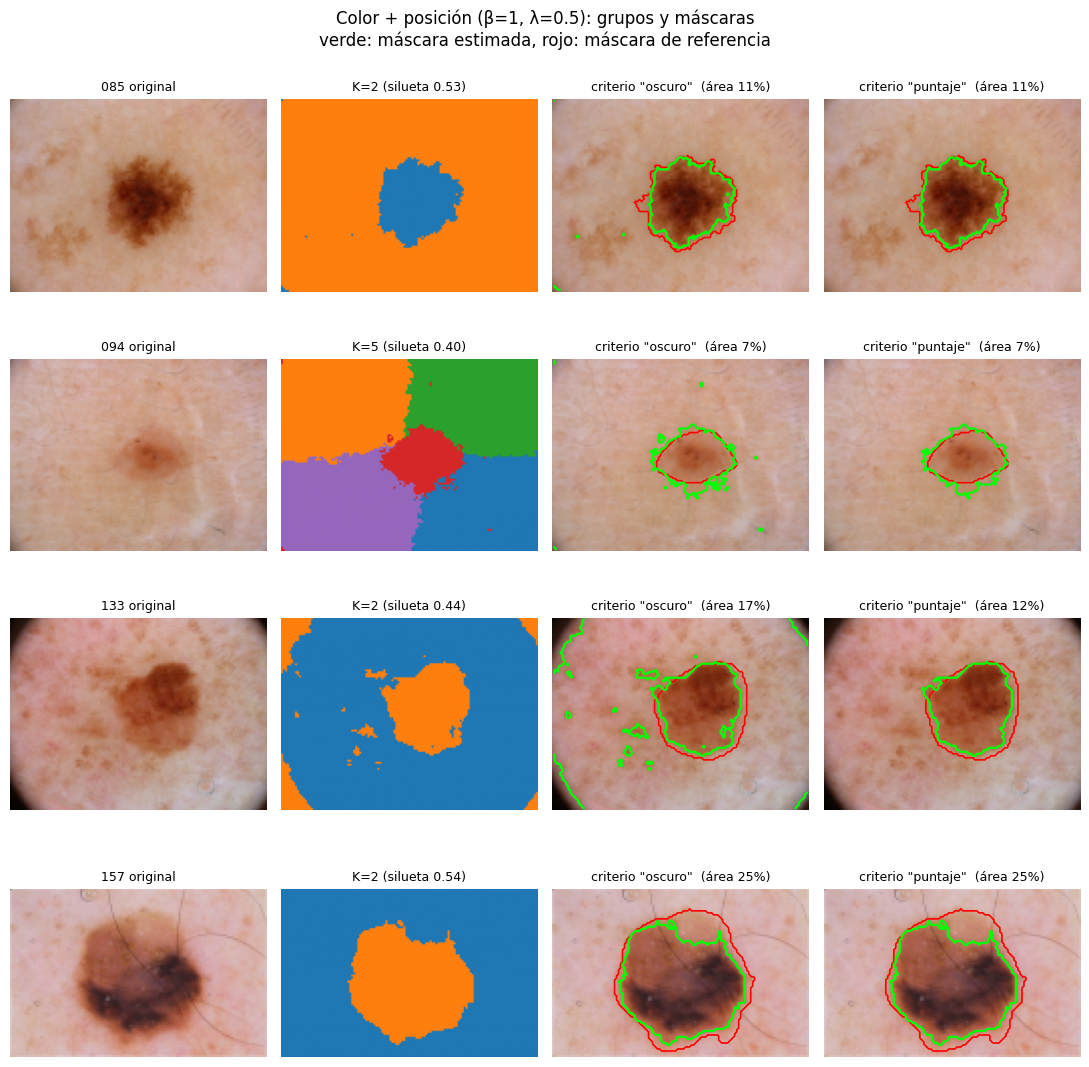

In [22]:
mostrar_mascaras('λ/β=0.5', ejemplos, 'Color + posición (β=1, λ=0.5): grupos y máscaras')

**Conclusiones de la inspección visual (solo imágenes de ajuste, comparando con las referencias):**

- En la **133**, con K = 2 la lesión y el viñeteado negro de las esquinas caen en el mismo grupo, el criterio 1 los incluye a ambos, y el criterio 2 elimina las esquinas al quedarse con la componente más grande, con un contorno muy cercano a la referencia.
- En la **094** (lesión de bajo contraste) el criterio 1 deja motas dispersas por la piel, mientras el criterio 2 las elimina, aunque queda un borde irregular en la parte inferior.
- En la **085** y la **157** las máscaras estimadas son **más pequeñas que la referencia**, dejan fuera la periferia más clara que los anotadores sí incluyeron. Con solo color y K = 2 el grupo *oscuro* no alcanza a cubrir esas zonas.
- En la **094** con λ/β ≥ 1 los grupos son tan compactos que la máscara se expande más allá de la lesión, creando una sobresegmentación.

## 4. Ajuste del método

Hasta aquí la selección de K y la construcción de la máscara se hicieron **sin usar las máscaras de referencia**. En esta sección usamos las referencias de las 15 imágenes de ajuste para **medir** la calidad de cada configuración y elegir una final. Una *configuración* es la combinación de:

- una razón **λ/β** (una de las 10 combinaciones de la sección 2), y
- un **criterio de construcción de la máscara** (`oscuro` o `puntaje` de la sección 3).

Para cada configuración y cada imagen se calculan dos métricas:

- **Coeficiente de Dice** entre la máscara estimada (Y) y la de referencia (X):
  $$\text{DICE}=\frac{2\,|X\cap Y|}{|X|+|Y|}$$
  Equivale al **F1-score a nivel de píxel** tomando la lesión como clase positiva, así que se calcula con `f1_score` de Scikit-learn sobre las máscaras aplanadas. Varía entre 0 (sin solape) y 1 (coincidencia perfecta).
- **V-measure** (`v_measure_score`) entre las etiquetas de K-medias y la máscara de referencia binaria. Mide si los grupos son coherentes con la división lesión/piel, **independientemente** de qué grupo se marque como lesión.

**Criterio de decisión:** el **Dice promedio** sobre las 15 imágenes es el criterio principal para elegir la configuración final; el V-measure se usa como información complementaria. Como se advierte en el enunciado, una buena silueta o un buen V-measure no garantizan una buena máscara, por eso Dice manda.


In [23]:
from sklearn.metrics import f1_score, v_measure_score, precision_score, recall_score


def dice(ref, est):
    # Dice = F1 a nivel de pixel con la lesion como clase positiva.
    r, e = ref.ravel(), est.ravel()
    if r.sum() == 0 and e.sum() == 0:
        return 1.0  # ambas vacias: coincidencia perfecta por convencion
    return f1_score(r, e, zero_division=0)


def v_measure_pixeles(etiquetas, ref):
    # Coherencia entre los grupos de K-medias y la particion lesion/piel.
    return v_measure_score(ref.ravel(), etiquetas.ravel())


### 4.1 Evaluación de todas las configuraciones

Se recorren las 10 combinaciones de (β, λ) y los 2 criterios de máscara. Las máscaras estimadas ya se calcularon en la sección 3 (diccionario `mascaras`) reutilizando el K elegido por silueta en la sección 2 (diccionario `mejores`), de modo que **no se vuelve a ejecutar K-medias**. Para cada combinación × criterio × imagen se calculan Dice, precisión y recall de la máscara, y el V-measure de los grupos (que solo depende de la combinación, no del criterio).


In [24]:
filas_eval = []
for (id_img, combo), mejor in mejores.items():
    etiquetas = mejor['etiquetas']
    ref = mascaras_ref[id_img]
    vm = v_measure_pixeles(etiquetas, ref)
    for criterio in criterios:                      # 'oscuro' y 'puntaje'
        est = mascaras[(id_img, combo, criterio)]
        r, e = ref.ravel(), est.ravel()
        filas_eval.append(dict(
            imagen=id_img, combo=combo, criterio=criterio, k=mejor['k'],
            silueta=mejor['silueta'],
            dice=dice(ref, est),
            precision=precision_score(r, e, zero_division=0),
            recall=recall_score(r, e, zero_division=0),
            v_measure=vm,
        ))

evaluacion = pd.DataFrame(filas_eval)
print(f'{len(evaluacion)} evaluaciones ({len(nombres_comb)} combinaciones x {len(criterios)} criterios x {len(ids_ajuste)} imagenes)')
evaluacion.head()


300 evaluaciones (10 combinaciones x 2 criterios x 15 imagenes)


,imagen,combo,criterio,k,silueta,dice,precision,recall,v_measure
0,ISIC_0000085,solo color,oscuro,2,0.793757,0.898287,0.989222,0.822663,0.749931
1,ISIC_0000085,solo color,puntaje,2,0.793757,0.902208,0.996902,0.823944,0.749931
2,ISIC_0000085,λ/β=0.1,oscuro,2,0.765360,0.898672,0.989231,0.823303,0.750581
3,ISIC_0000085,λ/β=0.1,puntaje,2,0.765360,0.902977,0.996906,0.825224,0.750581
4,ISIC_0000085,λ/β=0.25,oscuro,2,0.681412,0.898986,0.989992,0.823303,0.751792


### 4.2 Dice y V-measure promedio por configuración

Se promedian las métricas sobre las 15 imágenes de ajuste. La tabla se ordena por **Dice promedio** descendente, que es el criterio principal de selección.


In [25]:
resumen_cfg = (evaluacion.groupby(['combo', 'criterio'])
               .agg(dice_medio=('dice', 'mean'),
                    dice_std=('dice', 'std'),
                    precision_media=('precision', 'mean'),
                    recall_medio=('recall', 'mean'),
                    v_measure_medio=('v_measure', 'mean'),
                    k_mediana=('k', 'median'))
               .sort_values('dice_medio', ascending=False)
               .round(3))
resumen_cfg


,,dice_medio,dice_std,precision_media,recall_medio,v_measure_medio,k_mediana
combo,criterio,,,,,,
λ/β=0.25,puntaje,0.887,0.065,0.978,0.820,0.609,2.0
solo color,puntaje,0.883,0.064,0.967,0.824,0.639,2.0
λ/β=0.1,puntaje,0.882,0.064,0.967,0.825,0.638,2.0
λ/β=0.5,puntaje,0.877,0.062,0.971,0.811,0.522,2.0
λ/β=0.75,puntaje,0.864,0.069,0.957,0.806,0.324,5.0
λ/β=0.5,oscuro,0.857,0.078,0.928,0.812,0.522,2.0
λ/β=0.75,oscuro,0.853,0.072,0.932,0.808,0.324,5.0
λ/β=0.25,oscuro,0.850,0.106,0.914,0.818,0.609,2.0
solo color,oscuro,0.845,0.104,0.900,0.823,0.639,2.0


### 4.3 Selección de la configuración final

Se toma la configuración con **mayor Dice promedio**. También se identifican las **dos mejores** (para la visualización que pide el enunciado) y las configuraciones de referencia **solo color** y **solo posición**.


In [26]:
orden = resumen_cfg.reset_index()

# Mapa nombre de combinacion -> (beta, lam) para reportar los valores finales.
combo_a_betalam = {nombre_combinacion(b, l): (b, l) for b, l in combinaciones}

cfg_final = orden.iloc[0]
combo_final, criterio_final = cfg_final['combo'], cfg_final['criterio']
beta_final, lam_final = combo_a_betalam[combo_final]

dos_mejores = list(zip(orden['combo'].iloc[:2], orden['criterio'].iloc[:2]))

# Mejor criterio (por Dice) dentro de las combinaciones solo color / solo posicion.
def mejor_criterio_en(combo):
    sub = orden[orden.combo == combo].sort_values('dice_medio', ascending=False)
    return (combo, sub.iloc[0]['criterio'])

cfg_solo_color = mejor_criterio_en('solo color')
cfg_solo_pos = mejor_criterio_en('solo posición')

print('CONFIGURACION FINAL (mayor Dice promedio):')
print(f'  beta = {beta_final}, lambda = {lam_final}  ->  {combo_final}')
print(f'  criterio de mascara = "{criterio_final}"')
print(f'  Dice promedio = {cfg_final.dice_medio:.3f}  |  V-measure promedio = {cfg_final.v_measure_medio:.3f}')
print(f'  precision = {cfg_final.precision_media:.3f}  |  recall = {cfg_final.recall_medio:.3f}')
print()
print('Dos mejores configuraciones:', dos_mejores)
print('Referencia solo color     :', cfg_solo_color)
print('Referencia solo posicion  :', cfg_solo_pos)


CONFIGURACION FINAL (mayor Dice promedio):
  beta = 1.0, lambda = 0.25  ->  λ/β=0.25
  criterio de mascara = "puntaje"
  Dice promedio = 0.887  |  V-measure promedio = 0.609
  precision = 0.978  |  recall = 0.820

Dos mejores configuraciones: [('λ/β=0.25', 'puntaje'), ('solo color', 'puntaje')]
Referencia solo color     : ('solo color', 'puntaje')
Referencia solo posicion  : ('solo posición', 'puntaje')


### 4.4 Visualización de las configuraciones clave

Para las **dos configuraciones con mayor Dice promedio** y para las de **solo color** y **solo posición** se muestran, en cuatro imágenes representativas, la imagen original, los grupos de K-medias y la máscara estimada (verde) sobre la de referencia (rojo).


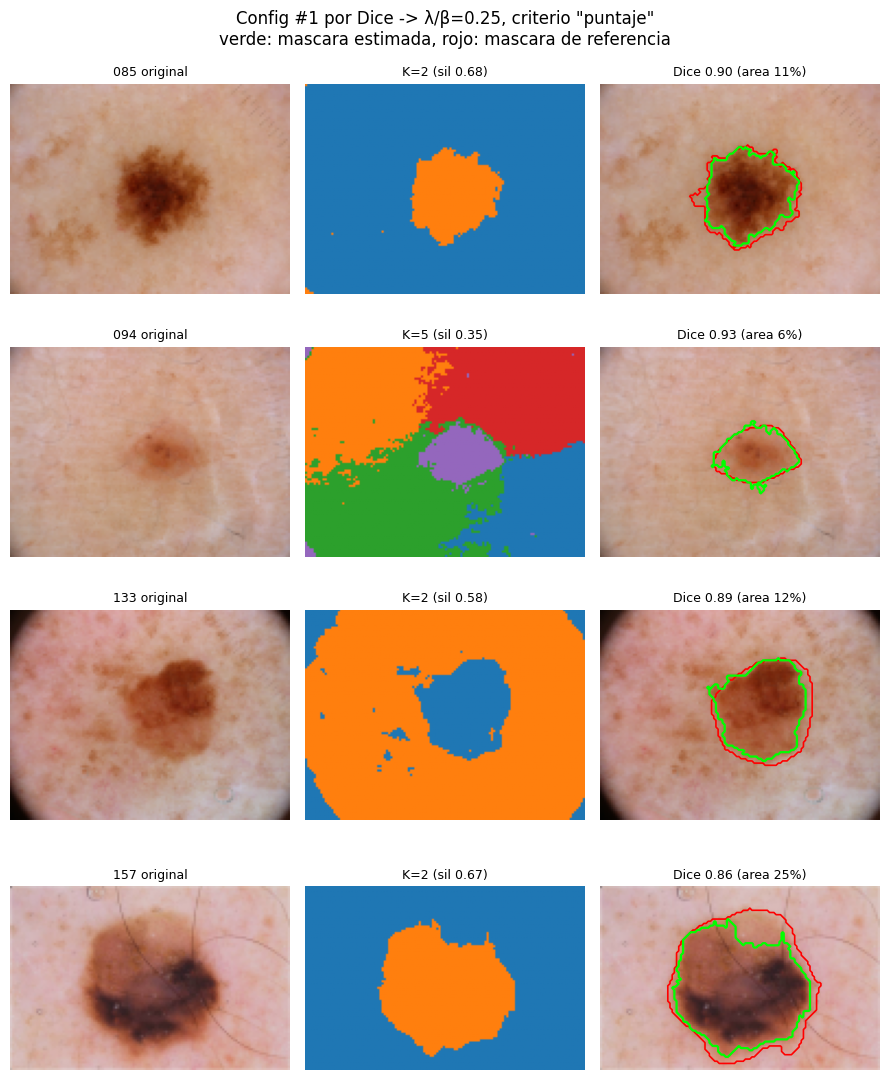

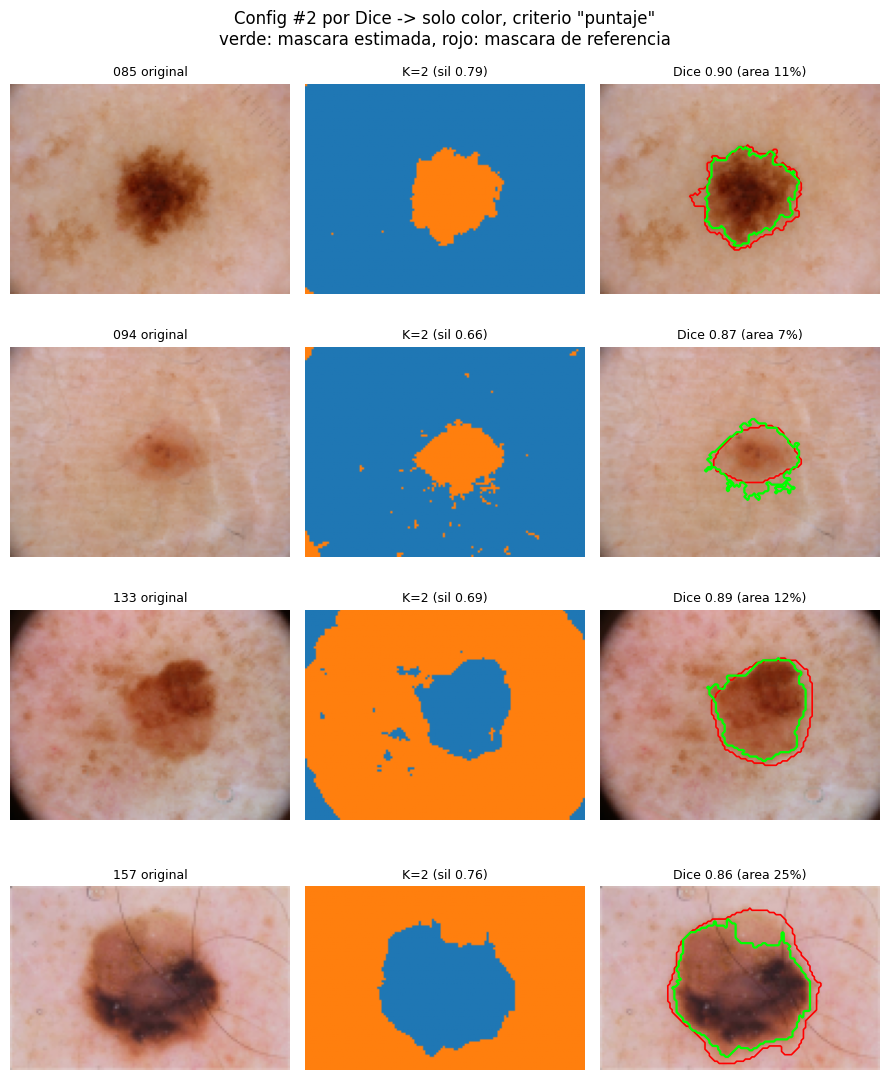

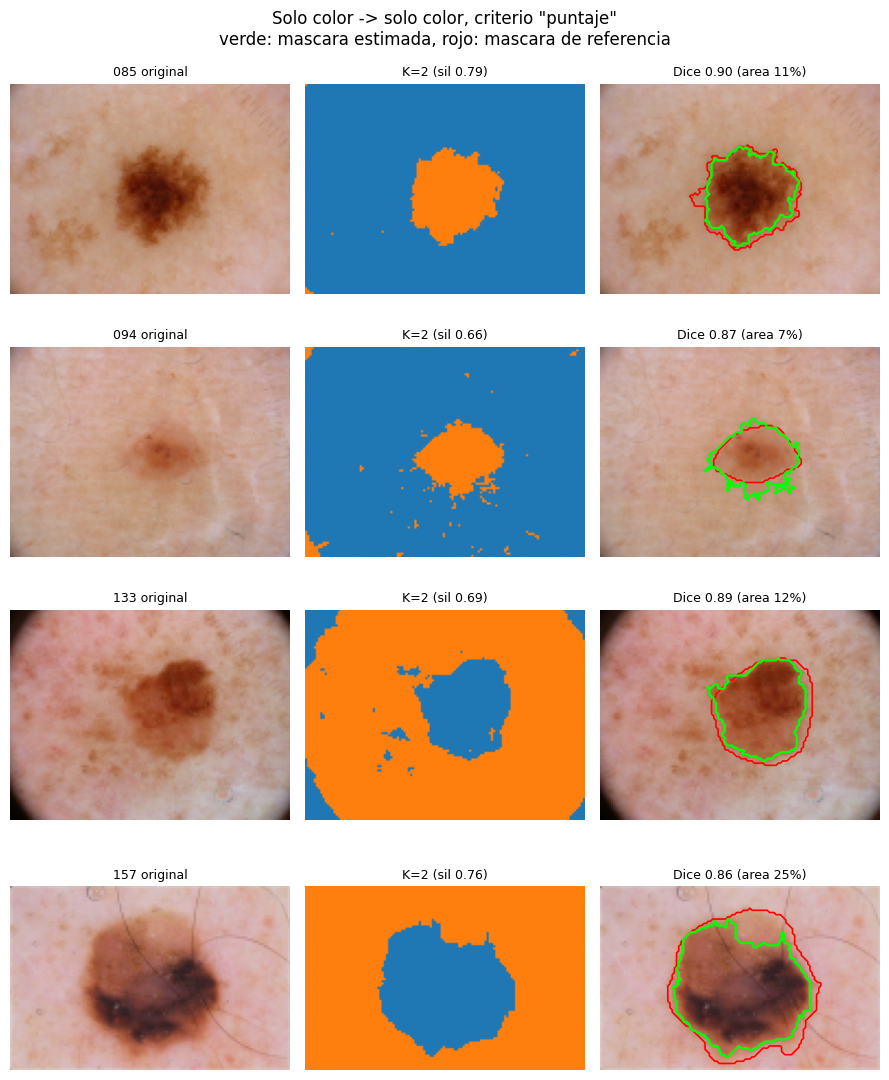

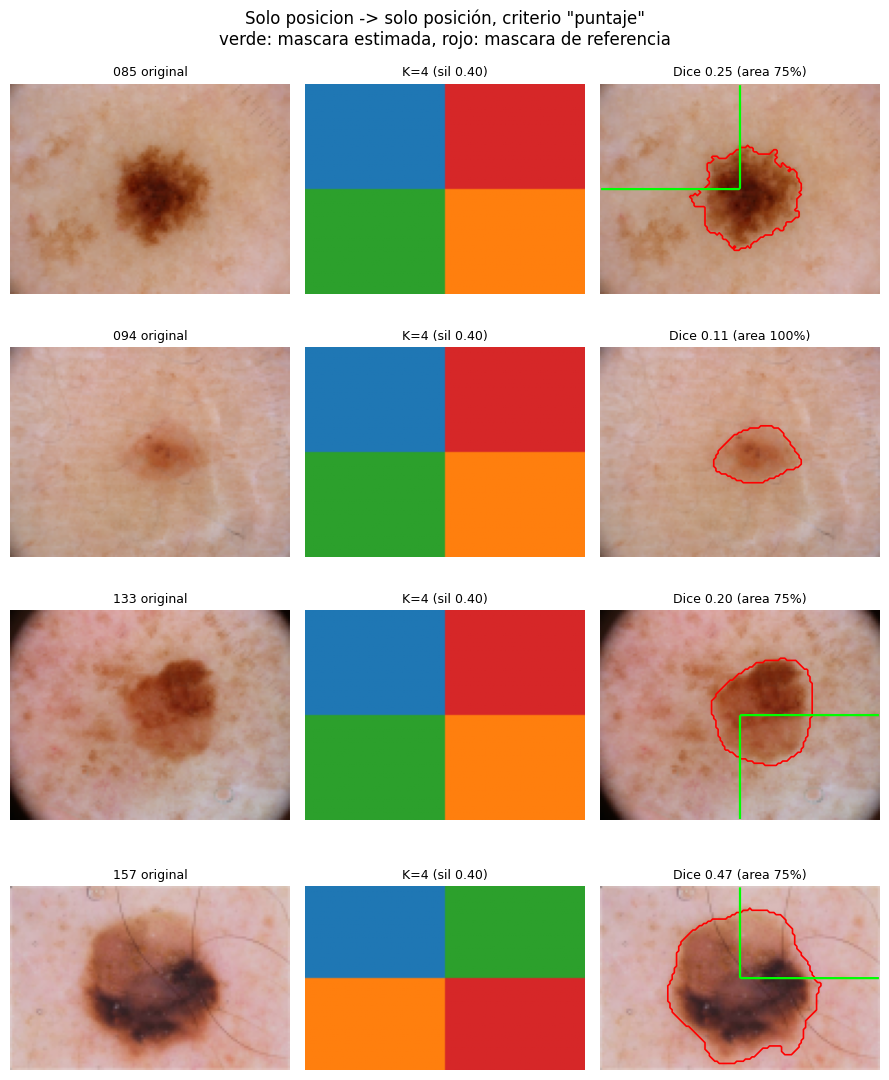

In [27]:
def mostrar_configuracion(combo, criterio, ids, titulo):
    fig, ejes = plt.subplots(len(ids), 3, layout='tight', figsize=(9, 2.7 * len(ids) + 0.6))
    ejes = np.atleast_2d(ejes)
    for fila, id_img in enumerate(ids):
        mejor = mejores[(id_img, combo)]
        est = mascaras[(id_img, combo, criterio)]
        d = dice(mascaras_ref[id_img], est)
        ejes[fila, 0].imshow(imagenes[id_img])
        ejes[fila, 0].set_title(f'{abreviar(id_img)} original', fontsize=9)
        ejes[fila, 1].imshow(mejor['etiquetas'], cmap='tab10', vmin=0, vmax=9)
        ejes[fila, 1].set_title(f"K={mejor['k']} (sil {mejor['silueta']:.2f})", fontsize=9)
        ejes[fila, 2].imshow(imagenes[id_img])
        ejes[fila, 2].contour(mascaras_ref[id_img], levels=[0.5], colors='red', linewidths=1.2)
        ejes[fila, 2].contour(est, levels=[0.5], colors='lime', linewidths=1.6)
        ejes[fila, 2].set_title(f'Dice {d:.2f} (area {est.mean():.0%})', fontsize=9)
    for eje in ejes.ravel():
        eje.axis('off')
    plt.suptitle(titulo + '\nverde: mascara estimada, rojo: mascara de referencia')
    plt.show()


ejemplos = ['ISIC_0000085', 'ISIC_0000094', 'ISIC_0000133', 'ISIC_0000157']

for i, (combo, criterio) in enumerate(dos_mejores, start=1):
    mostrar_configuracion(combo, criterio, ejemplos,
                          f'Config #{i} por Dice -> {combo}, criterio "{criterio}"')

mostrar_configuracion(*cfg_solo_color, ejemplos,
                      f'Solo color -> {cfg_solo_color[0]}, criterio "{cfg_solo_color[1]}"')
mostrar_configuracion(*cfg_solo_pos, ejemplos,
                      f'Solo posicion -> {cfg_solo_pos[0]}, criterio "{cfg_solo_pos[1]}"')


### 4.5 Casos de fallo en el ajuste

Se listan, para la configuración final, las imágenes con menor Dice. Esto ayuda a entender dónde falla el método antes de pasar a la prueba.


In [28]:
detalle_final = (evaluacion[(evaluacion.combo == combo_final) & (evaluacion.criterio == criterio_final)]
                 .set_index('imagen')[['k', 'silueta', 'dice', 'precision', 'recall', 'v_measure']]
                 .sort_values('dice'))
detalle_final.index = [abreviar(i) for i in detalle_final.index]
print(f'Configuracion final: {combo_final} (beta={beta_final}, lambda={lam_final}), criterio "{criterio_final}"')
print(f'Dice promedio de ajuste = {detalle_final.dice.mean():.3f}')
detalle_final.round(3)


Configuracion final: λ/β=0.25 (beta=1.0, lambda=0.25), criterio "puntaje"
Dice promedio de ajuste = 0.887


,k,silueta,dice,precision,recall,v_measure
116,2,0.608,0.760,0.999,0.613,0.482
112,2,0.510,0.782,1.000,0.643,0.427
150,2,0.639,0.790,1.000,0.652,0.572
114,2,0.586,0.858,0.821,0.898,0.373
157,2,0.667,0.858,1.000,0.751,0.627
133,2,0.585,0.887,0.980,0.810,0.421
085,2,0.681,0.903,0.998,0.825,0.752
122,2,0.565,0.904,0.992,0.830,0.673
108,2,0.713,0.912,0.999,0.839,0.766
156,2,0.716,0.921,0.999,0.855,0.698


**Lectura del ajuste.**

- El **Dice promedio** selecciona la configuración final por encima de alternativas con mejor silueta o V-measure, tal como advierte el enunciado: una partición limpia de píxeles no implica una buena máscara de la lesión.
- Las combinaciones **dominadas por color** (λ/β bajo) rinden mejor en Dice porque la lesión se distingue por tono, no por posición. El criterio **"puntaje"** aporta sobre el criterio "oscuro" el paso de limpieza (mayor componente conexa + relleno de huecos), que elimina motas y esquinas. Con **solo posición** la máscara es prácticamente arbitraria (Dice bajo), ya que sin color no hay forma de separar lesión de piel.
- Los **casos de fallo** típicos son lesiones de **bajo contraste** o con **periferia clara** que los anotadores incluyen pero el grupo de mayor contraste deja fuera (sub-segmentación), y lesiones muy grandes donde un λ alto infla la máscara con piel vecina (sobre-segmentación).

> *Nota: la redacción de la configuración final (β, λ y criterio) usa los valores calculados automáticamente en la celda 4.3, de modo que el texto queda alineado con lo que seleccionan las métricas al ejecutar el notebook.*


## 5. Evaluación y análisis en el conjunto de prueba

Se aplica la configuración final **sin ninguna modificación** a las **5 imágenes de prueba** (las que no se usaron en el ajuste). El procedimiento es idéntico al de ajuste:

1. cargar imagen y máscara de referencia al mismo tamaño (lado mayor 128, área / vecino más cercano),
2. para cada K de 2 a 8, ajustar K-medias con la razón λ/β final y elegir K por **silueta** sobre la misma muestra reproducible (2000 píxeles, semilla 2026),
3. construir la máscara con el criterio final,
4. medir K, silueta, Dice, V-measure, precisión y recall tomando la lesión como clase positiva.


In [29]:
ids_prueba = [i.split('.')[0] for i in sorted(os.listdir(dir_imgs)) if i.endswith('.jpg')]
ids_prueba = [i for i in ids_prueba if i not in ids_ajuste]
print('Imagenes de prueba:', [abreviar(i) for i in ids_prueba])

imagenes_prueba = {i: cargar_imagen(i) for i in ids_prueba}
mascaras_ref_prueba = {i: cargar_mascara_referencia(i, imagenes_prueba[i].shape[:2]) for i in ids_prueba}
for i in ids_prueba:
    assert mascaras_ref_prueba[i].shape == imagenes_prueba[i].shape[:2]
    assert set(np.unique(mascaras_ref_prueba[i])) <= {0, 1}
pd.Series({abreviar(i): imagenes_prueba[i].shape for i in ids_prueba}, name='forma (alto, ancho, canales)')


Imagenes de prueba: ['087', '105', '110', '123', '128']


087    (96, 128, 3)
105    (96, 128, 3)
110    (96, 128, 3)
123    (96, 128, 3)
128    (96, 128, 3)
Name: forma (alto, ancho, canales), dtype: object

In [30]:
criterio_final_fn = criterios[criterio_final]


def segmentar(imagen, beta, lam, criterio_fn, valores_k=rango_k, sem=semilla):
    """Selecciona K por silueta y construye la mascara con el criterio dado."""
    indices = indices_muestra_silueta(imagen.shape[0] * imagen.shape[1])
    pipeline = construir_pipeline(beta=beta, lam=lam)
    matriz = pipeline.named_steps['pixeles'].transform(imagen)
    mejor = (-np.inf, None, None)
    for k in valores_k:
        pipeline.set_params(kmeans__n_clusters=k)
        etiquetas = pipeline.fit_predict(imagen)
        hay_dos = len(np.unique(etiquetas[indices])) > 1
        sil = silhouette_score(matriz[indices], etiquetas[indices]) if hay_dos else np.nan
        if sil > mejor[0]:
            mejor = (sil, k, etiquetas.reshape(imagen.shape[:2]))
    sil, k, etiquetas = mejor
    mascara, _ = criterio_fn(imagen, etiquetas)
    return dict(k=k, silueta=sil, etiquetas=etiquetas, mascara=mascara)


resultado_prueba = {i: segmentar(imagenes_prueba[i], beta_final, lam_final, criterio_final_fn)
                    for i in ids_prueba}
print(f'Configuracion aplicada: beta={beta_final}, lambda={lam_final} ({combo_final}), criterio "{criterio_final}"')


Configuracion aplicada: beta=1.0, lambda=0.25 (λ/β=0.25), criterio "puntaje"


### 5.1 Tabla de resultados en prueba

Para cada imagen de prueba: K seleccionado, silueta, Dice, V-measure, precisión y recall (lesión como clase positiva).


In [31]:
filas_prueba = []
for i in ids_prueba:
    r = resultado_prueba[i]
    ref, est = mascaras_ref_prueba[i], r['mascara']
    filas_prueba.append(dict(
        imagen=abreviar(i), K=r['k'], silueta=r['silueta'],
        dice=dice(ref, est),
        v_measure=v_measure_pixeles(r['etiquetas'], ref),
        precision=precision_score(ref.ravel(), est.ravel(), zero_division=0),
        recall=recall_score(ref.ravel(), est.ravel(), zero_division=0),
    ))
tabla_prueba = pd.DataFrame(filas_prueba).set_index('imagen')
tabla_prueba.loc['PROMEDIO'] = tabla_prueba.mean()
tabla_prueba.round(3)


,K,silueta,dice,v_measure,precision,recall
imagen,,,,,,
087,2.0,0.643,0.883,0.634,1.000,0.790
105,2.0,0.691,0.917,0.742,0.996,0.849
110,2.0,0.576,0.757,0.320,1.000,0.609
123,2.0,0.664,0.911,0.726,0.860,0.967
128,2.0,0.706,0.932,0.816,0.999,0.874
PROMEDIO,2.0,0.656,0.880,0.648,0.971,0.818


### 5.2 Imagen original, máscara estimada y de referencia


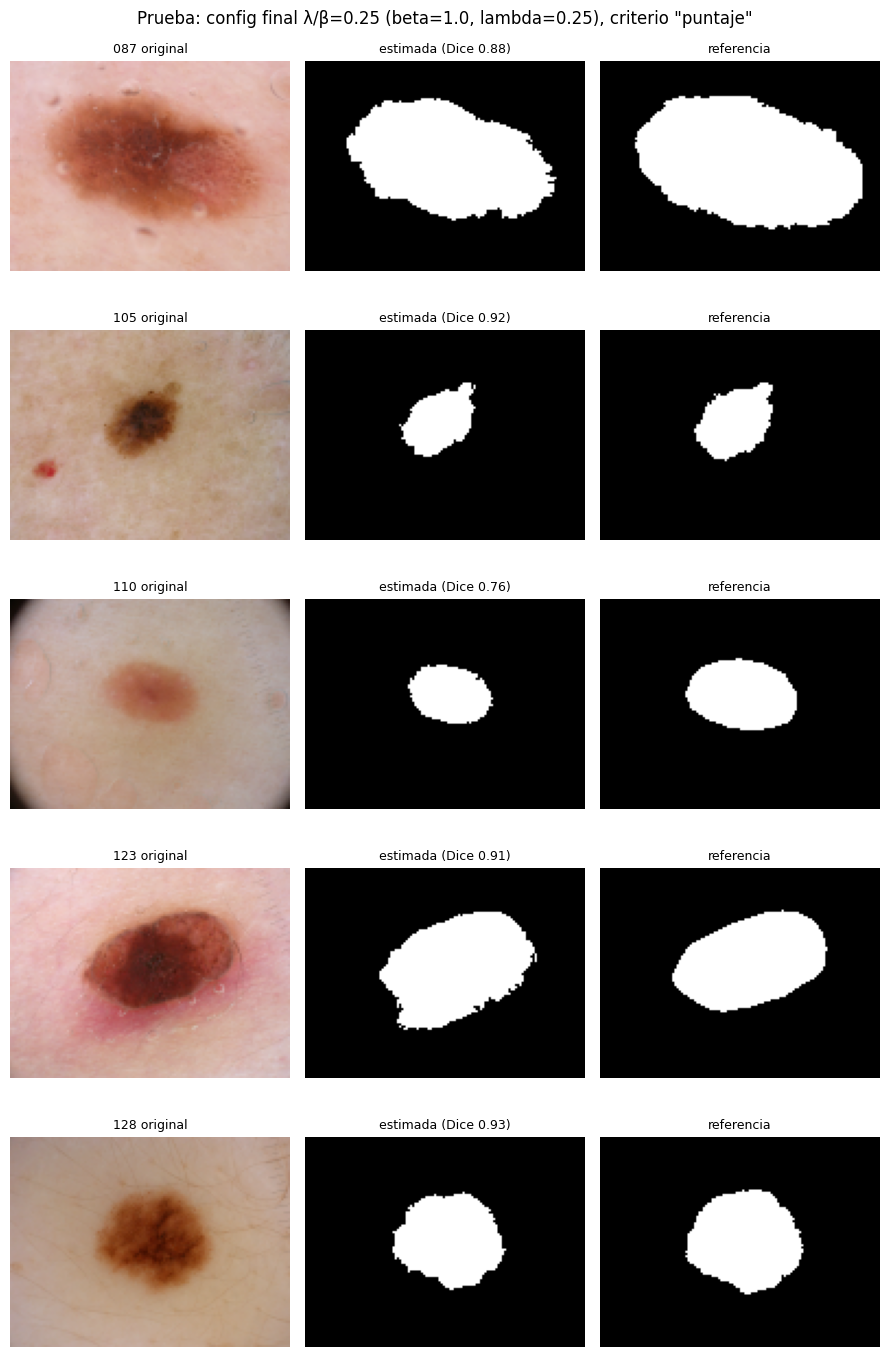

In [32]:
fig, ejes = plt.subplots(len(ids_prueba), 3, layout='tight', figsize=(9, 2.7 * len(ids_prueba) + 0.6))
ejes = np.atleast_2d(ejes)
for fila, i in enumerate(ids_prueba):
    r = resultado_prueba[i]
    est, ref = r['mascara'], mascaras_ref_prueba[i]
    ejes[fila, 0].imshow(imagenes_prueba[i])
    ejes[fila, 0].set_title(f'{abreviar(i)} original', fontsize=9)
    ejes[fila, 1].imshow(est, cmap='gray')
    ejes[fila, 1].set_title(f'estimada (Dice {dice(ref, est):.2f})', fontsize=9)
    ejes[fila, 2].imshow(ref, cmap='gray')
    ejes[fila, 2].set_title('referencia', fontsize=9)
for eje in ejes.ravel():
    eje.axis('off')
plt.suptitle(f'Prueba: config final {combo_final} (beta={beta_final}, lambda={lam_final}), criterio "{criterio_final}"')
plt.show()


### 5.3 Comparación ajuste vs prueba y análisis


In [33]:
dice_ajuste = detalle_final.dice.mean()
dice_prueba = tabla_prueba.loc[[i for i in tabla_prueba.index if i != 'PROMEDIO'], 'dice'].mean()
print(f'Dice promedio de ajuste (15 imagenes): {dice_ajuste:.3f}')
print(f'Dice promedio de prueba  (5 imagenes): {dice_prueba:.3f}')
print(f'Diferencia (prueba - ajuste)         : {dice_prueba - dice_ajuste:+.3f}')

sin_prom = tabla_prueba.drop(index='PROMEDIO')
mejor_img = sin_prom.dice.idxmax()
peor_img = sin_prom.dice.idxmin()
print(f'\nMejor imagen de prueba: {mejor_img} (Dice {sin_prom.dice.max():.3f})')
print(f'Peor imagen de prueba : {peor_img} (Dice {sin_prom.dice.min():.3f})')


Dice promedio de ajuste (15 imagenes): 0.887
Dice promedio de prueba  (5 imagenes): 0.880
Diferencia (prueba - ajuste)         : -0.007

Mejor imagen de prueba: 128 (Dice 0.932)
Peor imagen de prueba : 110 (Dice 0.757)


**Análisis de la evaluación.**

- La diferencia entre el **Dice promedio de ajuste y de prueba** indica cuánto generaliza la configuración elegida. Una caída moderada es esperable: la configuración se eligió para maximizar Dice en las 15 imágenes de ajuste, no en estas 5.
- Los **aciertos** se dan en lesiones bien contrastadas y centradas, donde el grupo oscuro/con mayor puntaje coincide con la referencia (precisión y recall altos a la vez).
- Los **errores** siguen los patrones ya vistos en ajuste: sub-segmentación en lesiones de borde difuso o periferia clara (recall bajo), y sobre-segmentación cuando hay estructuras oscuras no-lesión como vello, viñeteado de esquinas o artefactos (precisión baja). La reducción a 128 px también borra detalles finos.
- Tal como anticipa el enunciado, **no se espera un Dice alto en todas las imágenes**: el método es un segmentador no supervisado simple (K-medias + criterio por color/posición/forma) y sirve como primera aproximación, no como diagnóstico.

**Precauciones de uso (para DermAlpes):** la herramienta es una ayuda de pre-segmentación, no un diagnóstico; su calidad baja con vello, reflejos, marcas de regla o lesiones de bajo contraste, y la máscara siempre debería ser revisada por personal clínico antes de usarse.


## Análisis de resultados

Esta sección responde a las preguntas de discusión usando los números obtenidos en las secciones 2 a 5 (ajuste sobre 15 imágenes, prueba sobre 5). La configuración final fue **β = 1, λ = 0.25** (razón λ/β = 0.25) con el criterio **"puntaje"**.

### ¿Qué efecto tuvo incluir la posición de los píxeles?

Incluir la posición con un peso **pequeño** ayudó levemente, pero con un peso **grande** perjudicó de forma clara.

- Con la mejor razón, **λ/β = 0.25**, el Dice promedio de ajuste subió a **0.887**, apenas por encima de **solo color (0.883)**. La ganancia es marginal en promedio, pero concentrada en imágenes concretas: en la **094** (lesión de bajo contraste) el Dice pasó de **0.87** (solo color) a **0.93**. Un poco de información espacial actúa como regularizador: favorece que los píxeles de la lesión, que están juntos y hacia el centro, queden en el mismo grupo, y reduce las motas dispersas por la piel.
- Con peso espacial **alto** la segmentación se degrada: λ/β = 1 baja a **0.826**, λ/β = 4 a **0.588** y **solo posición** a **0.346**. Ejemplos de caída fuerte con λ/β = 4: **094** (0.11), **114** (0.04), **133** (0.21). La razón es que al dominar la posición K-medias parte la imagen en **regiones geométricas compactas** que mezclan lesión y piel; los grupos dejan de ser homogéneos en color y el criterio de máscara ya no puede separar la lesión. Con **solo posición** la partición no depende del contenido de la imagen, así que la máscara es prácticamente arbitraria.

En resumen: la posición ayuda solo como complemento menor del color (λ/β ≤ 0.25); en cuanto el color deja de dominar, perjudica.

### ¿Qué relación hay entre K, la silueta y el Dice? ¿Por qué no llevan a las mismas decisiones?

- **K y silueta.** Con color dominante (λ/β ≤ 0.25) la silueta elige casi siempre **K = 2** (lesión vs. piel) con silueta alta (≈ 0.62–0.75). Al subir λ, la estructura más "limpia" para K-medias pasa a ser una partición espacial y la silueta empieza a preferir **K = 5**, con silueta más baja (≈ 0.40–0.44).
- **Silueta y Dice.** Su correlación entre configuraciones es solo **moderada (≈ 0.56)**. La silueta mide qué tan compactos y separados son los grupos **en el espacio de características**, no si capturan la lesión. Con λ alto puede haber grupos espaciales razonablemente compactos (silueta no nula) que, sin embargo, dan un Dice pésimo.
- **V-measure y Dice.** La correlación es mayor (**≈ 0.84**) porque el V-measure sí compara contra la partición lesión/piel; aun así no coincide con Dice, porque mide la coherencia de **todos** los grupos y no el acierto de la **máscara final** (qué grupo se marca como lesión y cómo se limpia).

Por eso las tres métricas no conducen a la misma decisión: silueta y K se eligen **sin** las máscaras y optimizan la geometría de los grupos; Dice evalúa el objetivo real (la máscara de la lesión). Una agrupación con buena silueta o buen V-measure puede producir una máscara mediocre, tal como advierte el enunciado. De ahí que el Dice promedio sea el criterio principal de selección.

### ¿Cómo se comparan ajuste y prueba? ¿Por qué no modificar el método tras ver las máscaras de prueba?

- **Dice promedio de ajuste = 0.887** (15 imágenes) y **de prueba = 0.880** (5 imágenes): una diferencia de solo **−0.007**. El método **generaliza bien** y no muestra señales de sobreajuste a las imágenes de ajuste.
- En prueba, el **K = 2** y las métricas son consistentes con el ajuste: precisión muy alta (media **0.971**) y recall más bajo (media **0.818**). El mejor caso es la **128 (Dice 0.932)** y el peor la **110 (Dice 0.757, recall 0.609)**.
- **No se debe modificar el método después de consultar las máscaras de prueba** porque esas 5 imágenes son la estimación honesta de cómo rendirá con datos nuevos. Si se ajustaran β, λ, el criterio o K mirando sus máscaras, el conjunto de prueba dejaría de ser independiente: se convertiría en parte del ajuste y el Dice reportado sería **optimista** (fuga de información), sin reflejar el desempeño real ante casos no vistos.

### Dos limitaciones del modelo y sus causas

1. **Sub-segmentación de la periferia y de lesiones de bajo contraste (falsos negativos).** En prueba el **recall medio es 0.818** frente a una precisión de 0.971, y en la **110** el recall cae a **0.609**. Causa: en la representación **RGB + posición**, la periferia de la lesión tiene un color intermedio entre lesión y piel, así que K-medias con K = 2 la asigna al grupo de piel y el criterio por color/contraste la deja fuera. Las lesiones difusas (094, 114) apenas se separan del fondo. La reducción a 128 px agrava el problema al suavizar los bordes.
2. **Sensibilidad a estructuras oscuras que no son lesión (falsos positivos / fragmentación).** El criterio original "oscuro" incluye vello, viñeteado de esquinas y marcas; el paso de limpieza del criterio "puntaje" (mayor componente conexa + relleno) corrige buena parte, pero depende de que la lesión sea el objeto **central y más grande**. Causa: RGB no distingue "oscuro por pigmento" de "oscuro por vello o sombra", y las coordenadas solo ayudan si la lesión está realmente centrada; cuando no lo está, o compite con un artefacto grande, el criterio puede fallar.

### DermAlpes: consecuencias de falsos positivos/negativos, sesgos y generalización

- **Falsos negativos (perder lesión).** Son los más peligrosos clínicamente: una máscara que **subestima** la lesión puede llevar a medir mal su tamaño o a pasar por alto una zona relevante, con riesgo de **sub-diagnóstico**. El modelo tiende precisamente a esto (recall < precisión).
- **Falsos positivos (marcar piel sana como lesión).** Menos graves pero no inocuos: inflan el área estimada, pueden generar **alarmas o derivaciones innecesarias** y restar confianza en la herramienta.
- **Sesgos y generalización.** Las imágenes ISIC usadas tienen encuadre centrado, piel de tono claro y condiciones de captura homogéneas. El método asume que **la lesión es central, oscura y el objeto más grande**, supuestos que pueden romperse con: **tonos de piel más oscuros** (menor contraste lesión-piel), **lesiones amelanóticas o claras**, **vello abundante, reglas, tinta o reflejos**, lesiones **múltiples o descentradas**, y **otras cámaras/iluminación** que cambian el color RGB. Antes de usarlo con nuevas poblaciones o equipos habría que **re-validar** con imágenes representativas de esas condiciones.
- **Precaución de uso.** La herramienta es una **ayuda de pre-segmentación no supervisada**, no un diagnóstico. Su salida debe ser **revisada por personal clínico**, y conviene reportar los casos de bajo contraste o con artefactos como de baja confianza.


## Uso de herramientas de IA generativa

### Declaración del uso

- **Herramienta:** Claude (Anthropic), modelo Claude Sonnet 5.5, a través de la interfaz de chat.
- **Tipo de uso:** generación inicial de código para la **carga y lectura de las imágenes y de las máscaras de referencia**, y para **combinar las máscaras con las imágenes reales** en las visualizaciones (contornos de las máscaras superpuestos sobre cada imagen).
- **Facilitación de la redacción del markdown:** se usó la IA para ayudar a redactar las celdas de texto, por el formato específico que requiere el notebook.
- **Autocompletado para programar:** en los puntos 4 y 5 se utilizó autocompletado asistido por IA al escribir el código.
- **Revisión general:** se le pidió a la IA una revisión del notebook con el prompt "revisa este notebook y dime los errores posibles".

### Prompts utilizados

| # | Prompt | Qué produjo y dónde se usa |
|:-:|:---|:---|
| 1 | "Ayúdame a crear funciones para cargar las imágenes." | `cargar_imagen` y `cargar_mascara_referencia` (secciones 1.1 y 1.2): lectura de las imágenes en RGB y de las máscaras, que se convierten de 0/255 a 0/1. |
| 2 | "Ayúdame a crear funciones para poder visualizar las máscaras dentro de las imágenes reales." | Figura de la sección 1.2: contorno de la máscara de referencia dibujado sobre cada imagen de ajuste, con el porcentaje de lesión en el título. |
| 3 | "Normaliza las imágenes a 128 píxeles." | `forma_reducida` y el parámetro `lado_max = 128`: el lado mayor de cada imagen se reduce a 128 píxeles conservando la proporción, con interpolación por área para las imágenes y por vecino más cercano para las máscaras. |
| 4 | "Crea una función para mostrar las máscaras de cada criterio, el de oscuro y el de puntaje." | `mostrar_mascaras` (sección 3.4): para cada imagen muestra el original, los grupos de K-medias y la máscara estimada de cada criterio, con la máscara de referencia superpuesta. |
| 5 | "revisa este notebook y dime los errores posibles" | Revisión general del notebook para detectar errores posibles. |

### Análisis crítico del resultado

- **Partes correctas y útiles.** Las funciones de carga cumplieron lo que pide el enunciado para las máscaras: pasan de 0/255 a 0/1 y, al redimensionarse con vecino más cercano, conservan valores binarios. Esto se comprobó en el notebook con verificaciones de forma (misma que la imagen reducida) y de valores (solo 0 y 1), y visualmente los contornos de referencia coinciden con la lesión en las 15 imágenes de ajuste.
- **Errores, imprecisiones y limitaciones.**
  - La instrucción "normaliza a 128 píxeles" admite varias lecturas (reescalar los valores, o forzar un tamaño fijo de 128 × 128). Se interpretó como reducir el lado mayor a 128 píxeles conservando la proporción. Esta reducción pierde detalles finos (pelos, puntos pequeños), lo que se tiene en cuenta al interpretar los resultados.

### Aportes propios de los integrantes

- Se definieron los prompts que se utilizaron, la generación del pipeline también corrió por parte del grupo. Además de la propocición de ambos criterios para las creaciones de las mascaras. Adicionalmente, todos los análisis entregados sobre los resultados de la siueta de cada combinación y de cada criteior también fueron aportes de los integrantes.